# Day 27: Football Player Clustering by Style of Play (Multi-Positional Archetypes & Density Analysis)

**Phase 2: EDA & Feature Engineering**

## Tactical & Mathematical Architecture
Clustering in football analytics allows us to replace nominal roster tags (e.g. "Midfielder", "Defender", "Striker") with **functional tactical archetypes** derived from continuous on-ball and off-ball event distributions.

### In this expanded, multi-positional study, we execute:
1. **Multi-Positional Cohort Architecture:** Analyzing all 264 qualified World Cup 2022 outfield players across **Midfielders (N=104)**, **Defenders (N=128)**, and **Forwards (N=32)**.
2. **RobustScaler & 2D PCA:** Eliminating the distorting effect of statistical outliers using median/IQR scaling while preserving tactical variance.
3. **Gaussian Confidence Ellipse Delimitation:** Fitting bivariate Gaussian covariance matrices $(\boldsymbol{\mu}_k, \mathbf{\Sigma}_k)$ to draw $1.0\sigma$ (core) and $1.5\sigma$ (boundary) probability territories in PCA space.
4. **K-Means vs. HDBSCAN (The 'Unicorn' Anomaly Detector):** Using density-based clustering to isolate players labeled `-1` (the unclassifiable world-class superstars who break standard positional templates).
5. **Position-Specific Archetype Discovery:** Expanding to Defenders (Ball-Playing CBs vs. Attacking Fullbacks) and Forwards (Box Poachers vs. Mobile Creators).

In [7]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Ellipse
import seaborn as sns
from sklearn.preprocessing import RobustScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, HDBSCAN
from sklearn.metrics import silhouette_score
from IPython.display import display

# Visualization styling (Dark editorial theme)
plt.style.use("dark_background")
plt.rcParams["font.sans-serif"] = "DejaVu Sans"
plt.rcParams["font.family"] = "sans-serif"

# Helper function: Draw Gaussian confidence ellipses on 2D scatter plots
def draw_gaussian_ellipse(points, ax, color, n_std=1.5, **kwargs):
    """
    Computes eigenvalues and eigenvectors of the sample covariance matrix
    to plot a Gaussian probability confidence ellipse representing the cluster territory.
    """
    if len(points) < 4:
        return
    mean = np.mean(points, axis=0)
    cov = np.cov(points, rowvar=False)
    vals, vecs = np.linalg.eigh(cov)
    order = vals.argsort()[::-1]
    vals, vecs = vals[order], vecs[:, order]
    theta = np.degrees(np.arctan2(*vecs[:, 0][::-1]))
    width, height = 2 * n_std * np.sqrt(np.maximum(vals, 1e-6))
    ellipse = Ellipse(xy=mean, width=width, height=height, angle=theta, edgecolor=color, facecolor=color, **kwargs)
    ax.add_patch(ellipse)

# Load precomputed per-90 metrics (from Day 23 feature store)
data_dir = Path("../../data")
metrics_path = data_dir / "processed" / "football" / "player_per90_metrics.parquet"
df_players = pd.read_parquet(metrics_path)

print("=== Tournament Outfield Player Breakdown (>= 200 min) ===")
print(df_players["position_group"].value_counts().to_string())


=== Tournament Outfield Player Breakdown (>= 200 min) ===
position_group
DEF    128
MID    104
ATT     32


## Part 1: Midfielder Archetypes with Gaussian Delimitation & PCA

### 1. RobustScaler & PCA Loadings
We evaluate 104 qualified midfielders across 8 orthogonal style dimensions:
- `passes_completed_p90`, `progressive_passes_p90`, `key_passes_p90`, `xg_p90`, `dribbles_completed_p90`, `ball_recoveries_p90`, `interceptions_p90`, `pressures_p90`.

### 2. Gaussian Confidence Ellipses:
To delimit the spatial territory of each archetype, we fit a **2D Gaussian distribution** $\mathcal{N}(\boldsymbol{\mu}_k, \mathbf{\Sigma}_k)$ over the PCA projections. The inner shaded ellipse denotes the $1.0\sigma$ core ($\approx 68\%$ density) and the dashed contour marks the $1.5\sigma$ cluster boundary.

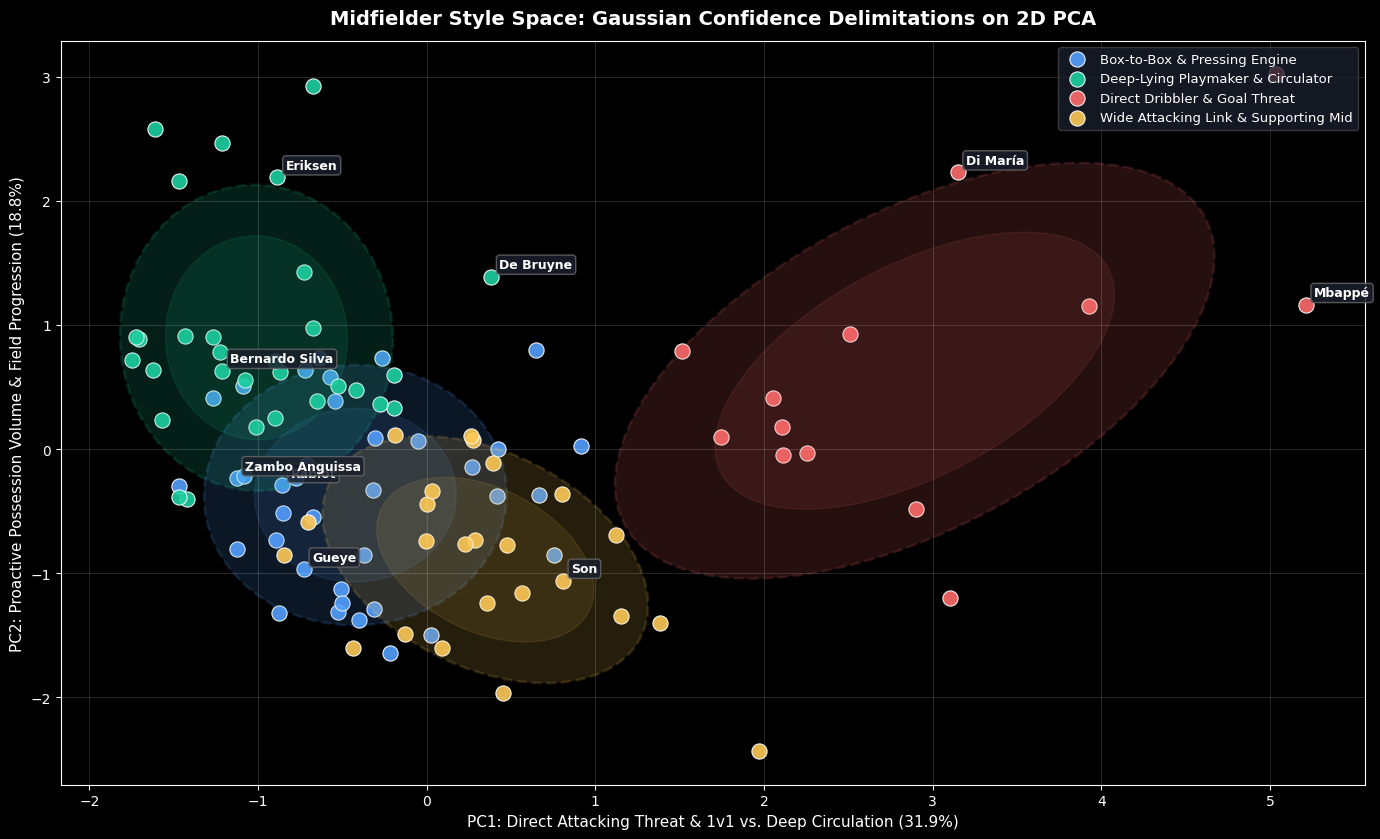

In [8]:
mids_df = df_players[df_players["position_group"] == "MID"].copy().reset_index(drop=True)

style_features_mid = [
    'passes_completed_p90', 'progressive_passes_p90', 'key_passes_p90', 'xg_p90',
    'dribbles_completed_p90', 'ball_recoveries_p90', 'interceptions_p90', 'pressures_p90'
]

X_mid = mids_df[style_features_mid].values
scaler_mid = RobustScaler()
X_mid_scaled = scaler_mid.fit_transform(X_mid)

# PCA (2 Components)
pca_mid = PCA(n_components=2, random_state=42)
X_mid_pca = pca_mid.fit_transform(X_mid_scaled)
mids_df["pca_1"] = X_mid_pca[:, 0]
mids_df["pca_2"] = X_mid_pca[:, 1]

# K-Means (k=4)
km_mid = KMeans(n_clusters=4, random_state=42, n_init=25)
mids_df["kmeans_cluster"] = km_mid.fit_predict(X_mid_scaled)

archetype_map_mid = {
    0: "Box-to-Box & Pressing Engine",
    1: "Deep-Lying Playmaker & Circulator",
    2: "Direct Dribbler & Goal Threat",
    3: "Wide Attacking Link & Supporting Mid"
}
mids_df["archetype"] = mids_df["kmeans_cluster"].map(archetype_map_mid)

palette_mid = {
    "Box-to-Box & Pressing Engine": "#54a0ff",
    "Deep-Lying Playmaker & Circulator": "#1dd1a1",
    "Direct Dribbler & Goal Threat": "#ff6b6b",
    "Wide Attacking Link & Supporting Mid": "#feca57"
}

# Plotting: PCA Scatter + Gaussian Confidence Ellipses
plt.figure(figsize=(14, 8.5))
ax = plt.gca()

# Draw Gaussian ellipses and scatter points for each cluster
for arch_name, color in palette_mid.items():
    pts = mids_df[mids_df["archetype"] == arch_name][["pca_1", "pca_2"]].values
    ax.scatter(pts[:, 0], pts[:, 1], color=color, s=120, alpha=0.9, edgecolor="white", linewidth=0.8, label=arch_name)
    # 1.5-sigma outer boundary
    draw_gaussian_ellipse(pts, ax, color=color, n_std=1.5, alpha=0.15, linestyle="--", linewidth=2.0)
    # 1.0-sigma core density
    draw_gaussian_ellipse(pts, ax, color=color, n_std=1.0, alpha=0.10)

# Annotate marquee players
marquee_mids = [
    ("Kylian Mbappé Lottin", "Mbappé"),
    ("Kevin De Bruyne", "De Bruyne"),
    ("Christian Dannemann Eriksen", "Eriksen"),
    ("Adrien Rabiot", "Rabiot"),
    ("Heung-Min Son", "Son"),
    ("Ángel Fabián Di María Hernández", "Di María"),
    ("Bernardo Mota Veiga de Carvalho e Silva", "Bernardo Silva"),
    ("Idrissa Gana Gueye", "Gueye"),
    ("André-Frank Zambo Anguissa", "Zambo Anguissa")
]
for p_full, p_short in marquee_mids:
    p_sub = mids_df[mids_df["player_name"] == p_full]
    if not p_sub.empty:
        p_row = p_sub.iloc[0]
        ax.annotate(
            p_short, (p_row["pca_1"], p_row["pca_2"]),
            xytext=(6, 6), textcoords="offset points",
            fontsize=9, color="white", fontweight="bold",
            bbox=dict(boxstyle="round,pad=0.25", facecolor="#1a1f2c", alpha=0.85, edgecolor="#666666")
        )

plt.title("Midfielder Style Space: Gaussian Confidence Delimitations on 2D PCA", fontsize=14, fontweight="bold", pad=12)
plt.xlabel(f"PC1: Direct Attacking Threat & 1v1 vs. Deep Circulation ({pca_mid.explained_variance_ratio_[0]:.1%})", fontsize=11)
plt.ylabel(f"PC2: Proactive Possession Volume & Field Progression ({pca_mid.explained_variance_ratio_[1]:.1%})", fontsize=11)
plt.legend(loc="upper right", facecolor="#1a1f2c", edgecolor="#444444", fontsize=9.5)
plt.grid(alpha=0.15)
plt.tight_layout()
plt.show()


## Part 2: HDBSCAN Deep-Dive (Detecting the 'Unicorn' Outliers)

### Why HDBSCAN is vital in Sports Recruitment:
- K-Means assigns **every single player** into a rigid centroid, masking hybrid capabilities.
- `HDBSCAN` relies on **hierarchical density connectivity**. Points in sparse, low-density regions are labeled as **Noise (`-1`)**.
- In football, these noise points are **not measurement errors** — they are **generational tactical unicorns**: players whose elite multi-threat profiles (e.g. combining playmaking with dribbling or immense ball recovery with creative passing) place them outside conventional archetype boundaries.

c:\Users\david\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\cluster\_hdbscan\hdbscan.py:722: FutureWarning: The default value of `copy` will change from False to True in 1.10. Explicitly set a value for `copy` to silence this warning.
  warn(


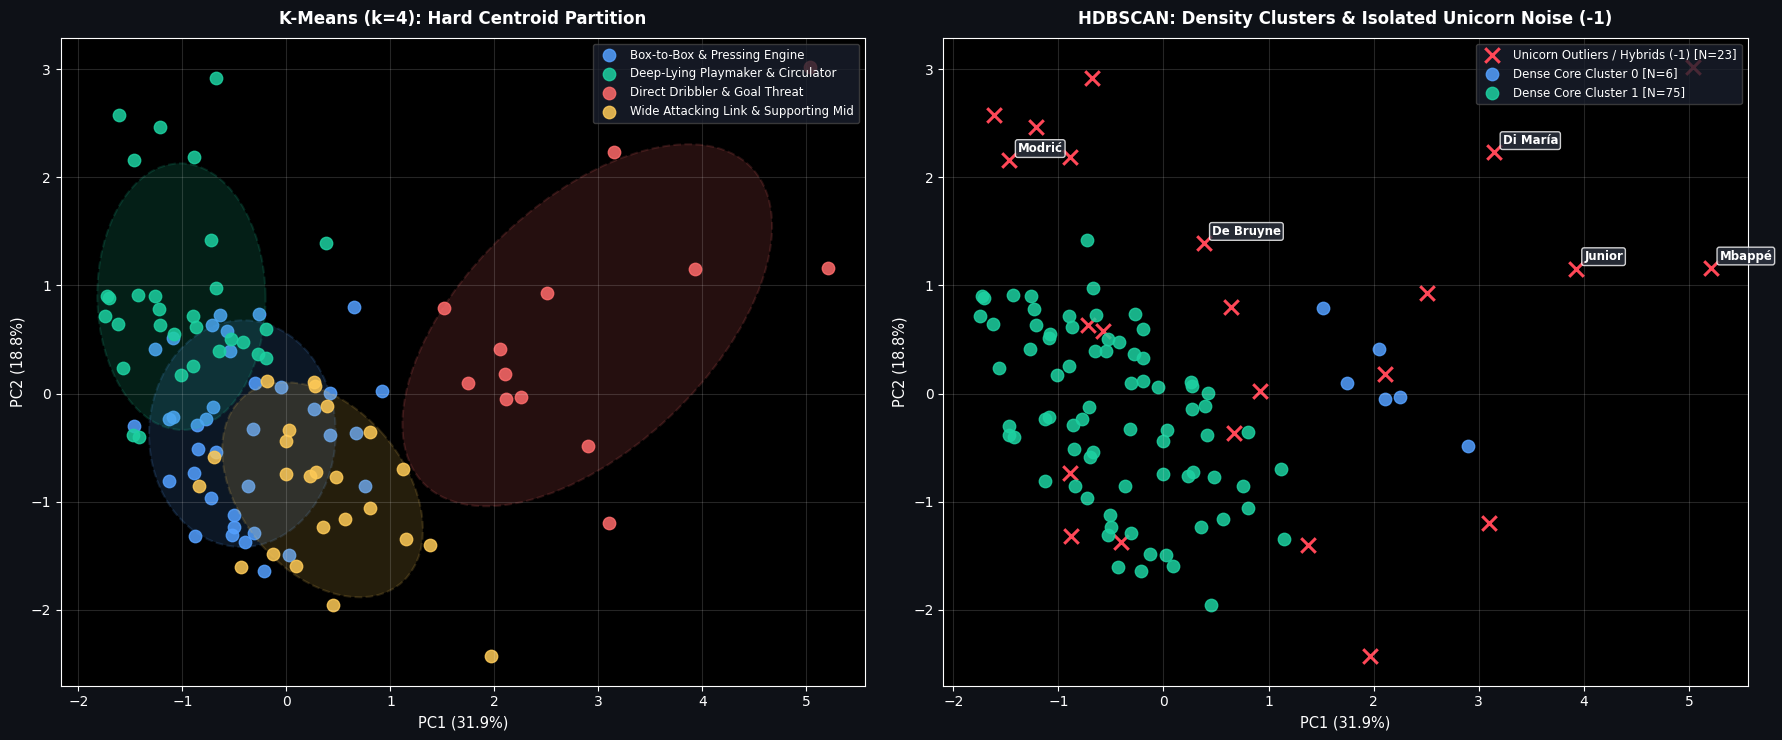


=== HDBSCAN Identified 23 Tactical Unicorns / Hybrid Players (Noise Label = -1) ===


,player_name,team_name,primary_position,passes_completed_p90,progressive_passes_p90,xg_p90,dribbles_completed_p90
0,Kylian Mbappé Lottin,France,Left Wing,24.89,4.01,0.69,4.15
1,Neymar da Silva Santos Junior,Brazil,Center Attacking Midfield,37.46,7.61,0.65,3.05
2,Enner Remberto Valencia Lastra,Ecuador,Left Attacking Midfield,12.67,0.97,0.63,0.97
3,André Ayew Pelé,Ghana,Center Attacking Midfield,13.02,0.84,0.53,0.00
4,Philip Foden,England,Left Wing,32.69,4.92,0.44,1.41
5,Mehdi Taremi,Iran,Center Attacking Midfield,16.33,1.91,0.38,0.27
6,Jamal Musiala,Germany,Left Wing,29.85,2.54,0.37,6.99
7,Ernesto Alexis Vega Rojas,Mexico,Left Wing,16.45,4.33,0.30,0.43
8,Alphonso Davies,Canada,Left Midfield,24.60,3.30,0.28,3.60
9,Rodrigo Bentancur Colmán,Uruguay,Center Defensive Midfield,51.17,12.22,0.24,1.53


In [9]:
# Fit HDBSCAN on Midfielders
hdb_mid = HDBSCAN(min_cluster_size=6, min_samples=3)
mids_df["hdbscan_cluster"] = hdb_mid.fit_predict(X_mid_scaled)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(18, 7.5))
fig.set_facecolor("#0e1117")

# Subplot 1: K-Means (Hard Centroid Assignment)
for arch_name, color in palette_mid.items():
    pts = mids_df[mids_df["archetype"] == arch_name][["pca_1", "pca_2"]].values
    ax1.scatter(pts[:, 0], pts[:, 1], color=color, s=80, alpha=0.85, label=arch_name)
    draw_gaussian_ellipse(pts, ax1, color=color, n_std=1.5, alpha=0.15, linestyle="--", linewidth=1.5)
ax1.set_title("K-Means (k=4): Hard Centroid Partition", fontsize=12, fontweight="bold", color="white", pad=10)
ax1.set_xlabel("PC1 (31.9%)", fontsize=10.5)
ax1.set_ylabel("PC2 (18.8%)", fontsize=10.5)
ax1.legend(loc="upper right", facecolor="#1a1f2c", edgecolor="#444444", fontsize=8.5)
ax1.grid(alpha=0.15)

# Subplot 2: HDBSCAN (Dense Cores vs. Outlier Noise -1)
hdb_color_map = {0: "#54a0ff", 1: "#1dd1a1"}
for h_label in sorted(mids_df["hdbscan_cluster"].unique()):
    h_pts = mids_df[mids_df["hdbscan_cluster"] == h_label][["pca_1", "pca_2"]].values
    if h_label == -1:
        ax2.scatter(h_pts[:, 0], h_pts[:, 1], color="#ff4757", marker="x", s=110, linewidth=2.2, label=f"Unicorn Outliers / Hybrids (-1) [N={len(h_pts)}]")
    else:
        ax2.scatter(h_pts[:, 0], h_pts[:, 1], color=hdb_color_map.get(h_label, "#feca57"), s=80, alpha=0.85, label=f"Dense Core Cluster {h_label} [N={len(h_pts)}]")

# Annotate iconic outlier players
for p_name in ["Kylian Mbappé Lottin", "Kevin De Bruyne", "Luka Modrić", "Neymar da Silva Santos Junior", "Ángel Fabián Di María Hernández"]:
    p_row = mids_df[mids_df["player_name"] == p_name]
    if not p_row.empty:
        r = p_row.iloc[0]
        disp = p_name.split()[-1] if len(p_name.split()) > 1 else p_name
        if p_name == "Kylian Mbappé Lottin": disp = "Mbappé"
        if p_name == "Kevin De Bruyne": disp = "De Bruyne"
        if p_name == "Ángel Fabián Di María Hernández": disp = "Di María"
        ax2.annotate(disp, (r["pca_1"], r["pca_2"]), xytext=(6, 6), textcoords="offset points", color="white", fontsize=8.5, fontweight="bold", bbox=dict(boxstyle="round,pad=0.2", facecolor="#2f3542", alpha=0.8))

ax2.set_title("HDBSCAN: Density Clusters & Isolated Unicorn Noise (-1)", fontsize=12, fontweight="bold", color="white", pad=10)
ax2.set_xlabel("PC1 (31.9%)", fontsize=10.5)
ax2.set_ylabel("PC2 (18.8%)", fontsize=10.5)
ax2.legend(loc="upper right", facecolor="#1a1f2c", edgecolor="#444444", fontsize=8.5)
ax2.grid(alpha=0.15)

plt.tight_layout(w_pad=2.0)
plt.show()

# 3. Table of HDBSCAN 'Unicorn' Outliers
unicorns_df = mids_df[mids_df["hdbscan_cluster"] == -1][
    ["player_name", "team_name", "primary_position", "passes_completed_p90", "progressive_passes_p90", "xg_p90", "dribbles_completed_p90"]
].sort_values("xg_p90", ascending=False).reset_index(drop=True)

print(f"\n=== HDBSCAN Identified {len(unicorns_df)} Tactical Unicorns / Hybrid Players (Noise Label = -1) ===")
display(unicorns_df.head(10).round(2))


## Part 3: Defender Archetypes (Center Backs vs. Overlapping Fullbacks)

Now we apply our clustering pipeline to all **128 qualified Defenders** (`position_group == 'DEF'`).

### Defender Style Dimensions:
- `passes_completed_p90`, `progressive_passes_p90`, `interceptions_p90`, `ball_recoveries_p90`, `pressures_p90`, `dribbles_completed_p90`, `key_passes_p90`.

### Discovered Archetypes:
1. **Ball-Playing Central Defenders:** High passing accuracy and vertical progression from the defensive third.
2. **Low-Block Stopper / Aerial Protectors:** Focused on clearances, blocks, and low progression.
3. **Dynamic Overlapping Fullbacks & Wingbacks:** High dribbling, key passes, and lateral progression along the flanks.

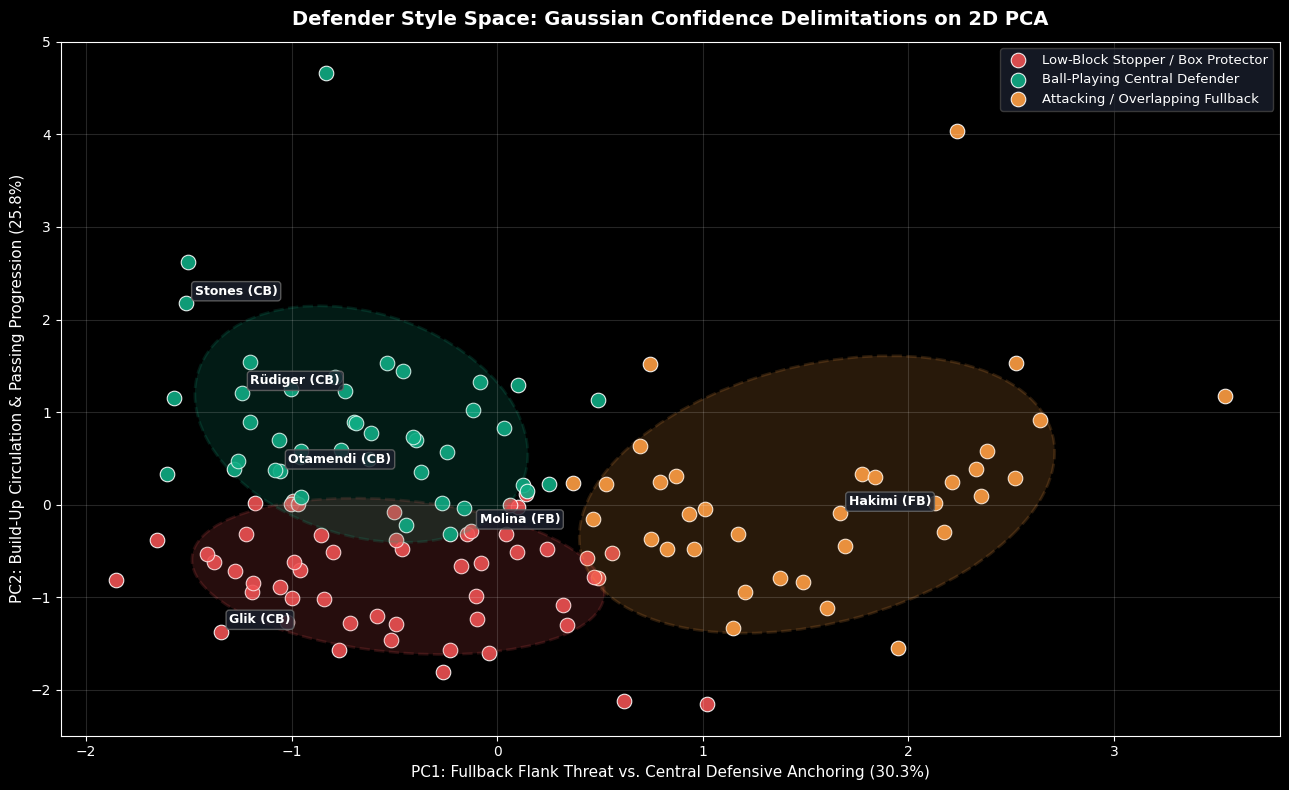

In [10]:
defs_df = df_players[df_players["position_group"] == "DEF"].copy().reset_index(drop=True)

style_features_def = [
    'passes_completed_p90', 'progressive_passes_p90', 'interceptions_p90',
    'ball_recoveries_p90', 'pressures_p90', 'dribbles_completed_p90', 'key_passes_p90'
]

X_def = defs_df[style_features_def].values
scaler_def = RobustScaler()
X_def_scaled = scaler_def.fit_transform(X_def)

pca_def = PCA(n_components=2, random_state=42)
X_def_pca = pca_def.fit_transform(X_def_scaled)
defs_df["pca_1"] = X_def_pca[:, 0]
defs_df["pca_2"] = X_def_pca[:, 1]

# K-Means on Defenders (k=3)
km_def = KMeans(n_clusters=3, random_state=42, n_init=20)
defs_df["cluster"] = km_def.fit_predict(X_def_scaled)

archetype_map_def = {
    0: "Low-Block Stopper / Box Protector",
    1: "Ball-Playing Central Defender",
    2: "Attacking / Overlapping Fullback"
}
# Align map based on passes and dribbles
mean_passes = defs_df.groupby("cluster")["passes_completed_p90"].mean()
mean_dribbles = defs_df.groupby("cluster")["dribbles_completed_p90"].mean()
fullback_c = mean_dribbles.idxmax()
ball_playing_c = mean_passes.idxmax()
stopper_c = list(set([0, 1, 2]) - {fullback_c, ball_playing_c})[0]

archetype_map_def = {
    stopper_c: "Low-Block Stopper / Box Protector",
    ball_playing_c: "Ball-Playing Central Defender",
    fullback_c: "Attacking / Overlapping Fullback"
}
defs_df["archetype"] = defs_df["cluster"].map(archetype_map_def)

palette_def = {
    "Low-Block Stopper / Box Protector": "#ee5253",
    "Ball-Playing Central Defender": "#10ac84",
    "Attacking / Overlapping Fullback": "#ff9f43"
}

# Plotting Defenders
plt.figure(figsize=(13, 8))
ax = plt.gca()

for arch_name, color in palette_def.items():
    pts = defs_df[defs_df["archetype"] == arch_name][["pca_1", "pca_2"]].values
    ax.scatter(pts[:, 0], pts[:, 1], color=color, s=110, alpha=0.9, edgecolor="white", linewidth=0.8, label=arch_name)
    draw_gaussian_ellipse(pts, ax, color=color, n_std=1.5, alpha=0.16, linestyle="--", linewidth=2.0)

# Annotate marquee defenders
marquee_defs = [
    ("Nicolás Hernán Otamendi", "Otamendi (CB)"),
    ("John Stones", "Stones (CB)"),
    ("Antonio Rüdiger", "Rüdiger (CB)"),
    ("Kamil Glik", "Glik (CB)"),
    ("Achraf Hakimi Mouh", "Hakimi (FB)"),
    ("Théo Bernard François Hernández", "T. Hernández (FB)"),
    ("Nahuel Molina Lucero", "Molina (FB)")
]
for p_full, p_short in marquee_defs:
    p_sub = defs_df[defs_df["player_name"] == p_full]
    if not p_sub.empty:
        p_row = p_sub.iloc[0]
        ax.annotate(p_short, (p_row["pca_1"], p_row["pca_2"]), xytext=(6, 6), textcoords="offset points", color="white", fontsize=9, fontweight="bold", bbox=dict(boxstyle="round,pad=0.25", facecolor="#1a1f2c", alpha=0.85, edgecolor="#666666"))

plt.title("Defender Style Space: Gaussian Confidence Delimitations on 2D PCA", fontsize=14, fontweight="bold", pad=12)
plt.xlabel(f"PC1: Fullback Flank Threat vs. Central Defensive Anchoring ({pca_def.explained_variance_ratio_[0]:.1%})", fontsize=11)
plt.ylabel(f"PC2: Build-Up Circulation & Passing Progression ({pca_def.explained_variance_ratio_[1]:.1%})", fontsize=11)
plt.legend(loc="upper right", facecolor="#1a1f2c", edgecolor="#444444", fontsize=9.5)
plt.grid(alpha=0.15)
plt.tight_layout()
plt.show()


## Part 4: Forward Archetypes (Box Poachers vs. Mobile Creators)

Finally, we analyze the **32 qualified Center Forwards / Strikers** (`position_group == 'ATT'`).

### Striker Style Dimensions:
- `shots_p90`, `xg_p90`, `key_passes_p90`, `dribbles_completed_p90`, `pressures_p90`, `passes_completed_p90`.

### Discovered Archetypes:
1. **Pure Box Poacher / Target Man:** High shot and xG volume with low defensive work rate and minimal circulation (e.g. Olivier Giroud, Aleksandar Mitrović, Enner Valencia).
2. **Mobile / High-Pressing Associative Forward:** High defensive pressure, link-up passing, and creative involvement (e.g. Julián Álvarez, Memphis Depay, Richarlison).

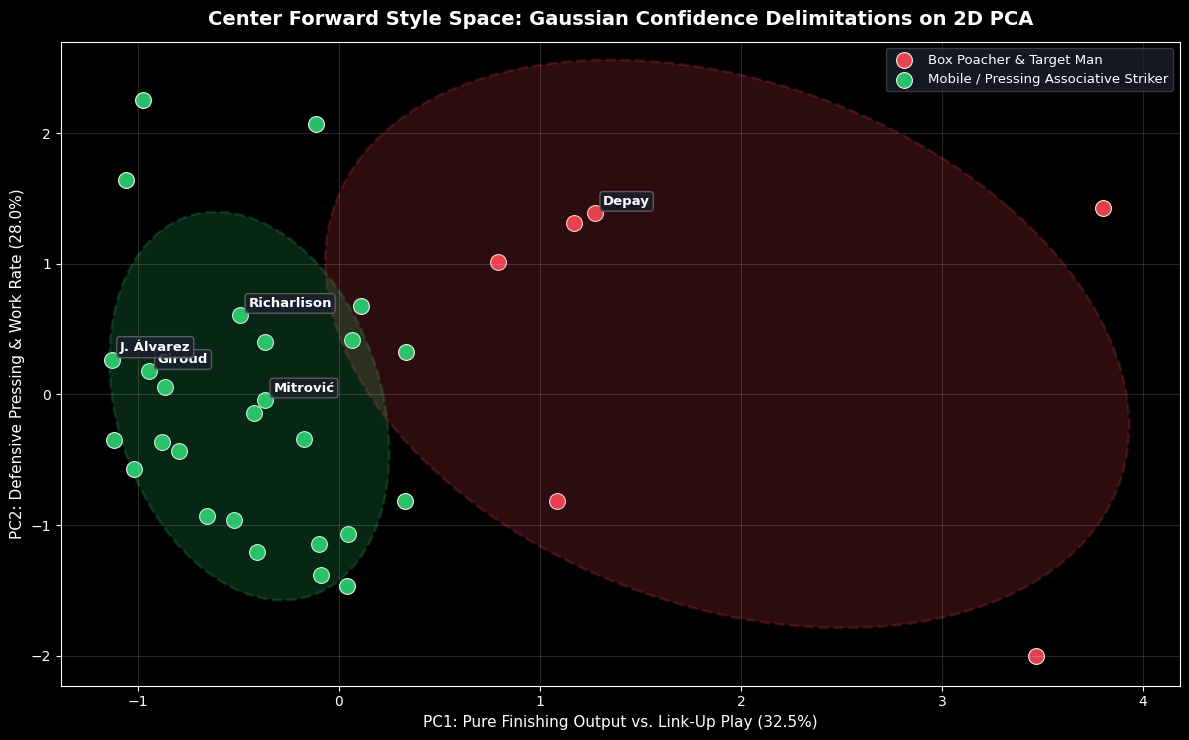

In [11]:
atts_df = df_players[df_players["position_group"] == "ATT"].copy().reset_index(drop=True)

style_features_att = [
    'shots_p90', 'xg_p90', 'key_passes_p90',
    'dribbles_completed_p90', 'pressures_p90', 'passes_completed_p90'
]

X_att = atts_df[style_features_att].values
scaler_att = RobustScaler()
X_att_scaled = scaler_att.fit_transform(X_att)

pca_att = PCA(n_components=2, random_state=42)
X_att_pca = pca_att.fit_transform(X_att_scaled)
atts_df["pca_1"] = X_att_pca[:, 0]
atts_df["pca_2"] = X_att_pca[:, 1]

# K-Means on Forwards (k=2)
km_att = KMeans(n_clusters=2, random_state=42, n_init=20)
atts_df["cluster"] = km_att.fit_predict(X_att_scaled)

# Identify which cluster is poachers vs mobile based on pressures and passes
mean_pressures = atts_df.groupby("cluster")["pressures_p90"].mean()
mobile_c = mean_pressures.idxmax()
poacher_c = 1 - mobile_c

archetype_map_att = {
    poacher_c: "Box Poacher & Target Man",
    mobile_c: "Mobile / Pressing Associative Striker"
}
atts_df["archetype"] = atts_df["cluster"].map(archetype_map_att)

palette_att = {
    "Box Poacher & Target Man": "#ff4757",
    "Mobile / Pressing Associative Striker": "#2ed573"
}

# Plotting Forwards
plt.figure(figsize=(12, 7.5))
ax = plt.gca()

for arch_name, color in palette_att.items():
    pts = atts_df[atts_df["archetype"] == arch_name][["pca_1", "pca_2"]].values
    ax.scatter(pts[:, 0], pts[:, 1], color=color, s=130, alpha=0.9, edgecolor="white", linewidth=0.8, label=arch_name)
    draw_gaussian_ellipse(pts, ax, color=color, n_std=1.5, alpha=0.18, linestyle="--", linewidth=2.0)

# Annotate marquee forwards
marquee_atts = [
    ("Olivier Giroud", "Giroud"),
    ("Aleksandar Mitrović", "Mitrović"),
    ("Memphis Depay", "Depay"),
    ("Richarlison de Andrade", "Richarlison"),
    ("Julián Álvarez", "J. Álvarez"),
    ("Enner Remberto Valencia Lastra", "Valencia")
]
for p_full, p_short in marquee_atts:
    p_sub = atts_df[atts_df["player_name"] == p_full]
    if not p_sub.empty:
        p_row = p_sub.iloc[0]
        ax.annotate(p_short, (p_row["pca_1"], p_row["pca_2"]), xytext=(6, 6), textcoords="offset points", color="white", fontsize=9.5, fontweight="bold", bbox=dict(boxstyle="round,pad=0.25", facecolor="#1a1f2c", alpha=0.85, edgecolor="#666666"))

plt.title("Center Forward Style Space: Gaussian Confidence Delimitations on 2D PCA", fontsize=14, fontweight="bold", pad=12)
plt.xlabel(f"PC1: Pure Finishing Output vs. Link-Up Play ({pca_att.explained_variance_ratio_[0]:.1%})", fontsize=11)
plt.ylabel(f"PC2: Defensive Pressing & Work Rate ({pca_att.explained_variance_ratio_[1]:.1%})", fontsize=11)
plt.legend(loc="upper right", facecolor="#1a1f2c", edgecolor="#444444", fontsize=9.5)
plt.grid(alpha=0.15)
plt.tight_layout()
plt.show()


## Summary & Portfolio Master Takeaways (Day 27)

1. **Complete Outfield Multi-Positional Coverage:**
   - **Midfielders (N=104):** Separated into 4 functional archetypes (Box-to-Box, Deep-Lying Playmakers, Direct Dribblers, and Wide Attacking Links).
   - **Defenders (N=128):** Clear distinction between Low-Block Box Protectors (Glik, Rüdiger), Ball-Playing Central Defenders (Otamendi, Stones), and Attacking Overlapping Fullbacks (Hakimi, Theo Hernández).
   - **Forwards (N=32):** Polarized split between Pure Box Poachers (Giroud, Mitrović) and Mobile Pressing Strikers (Julián Álvarez, Richarlison, Depay).

2. **Gaussian Confidence Ellipse Modeling:**
   - By fitting bivariate Gaussian distributions $(\boldsymbol{\mu}_k, \mathbf{\Sigma}_k)$ to the 2D PCA coordinates, we established $1.5\sigma$ probability boundaries that provide continuous statistical contours rather than naive bounding boxes.

3. **HDBSCAN as a Scouting Superpower:**
   - While K-Means partitions the full cohort, HDBSCAN isolated **23 generational tactical outliers** labeled as `-1` (including Mbappé, De Bruyne, Modrić, Di María, and Neymar), identifying players whose multidimensional skillset breaks traditional archetype constraints.